# Evaluasi test: Lapis 1, E1, E6 fairness, E8 dampak guru, robustness
Semua dari `scripts/final_eval.py` (run `20261119-0652_final_eval`, segel `reports/TEST_OPENED.json`).

In [1]:
import json
import pandas as pd
from IPython.display import Image, Markdown, display
from remediaide_ml.paths import TABLES, FIGURES, PROCESSED
pd.set_option("display.precision", 4)
def js(name): return json.loads((TABLES / name).read_text())

## E1 — aturan v1 di test

In [2]:
pd.read_csv(TABLES / 'E1_b0_test.csv')

,metrik,nilai,ci_lo,ci_hi,n_baris,split
0,tingkat salah kelompok (4 kelas),0.4505,0.4314,0.4693,58963,test (20% siswa)
1,macro-F1 (4 kelas),0.3917,0.3799,0.4026,58963,test (20% siswa)
2,% 'Paham' B0 yang belum tuntas berikutnya,0.2775,0.2568,0.2997,58963,test (20% siswa)
3,% 'Miskonsepsi' B0 yang tuntas berikutnya,0.5240,0.5041,0.5443,58963,test (20% siswa)
4,error biner butuh_remediasi,0.3672,0.3588,0.3755,226432,test (20% siswa)


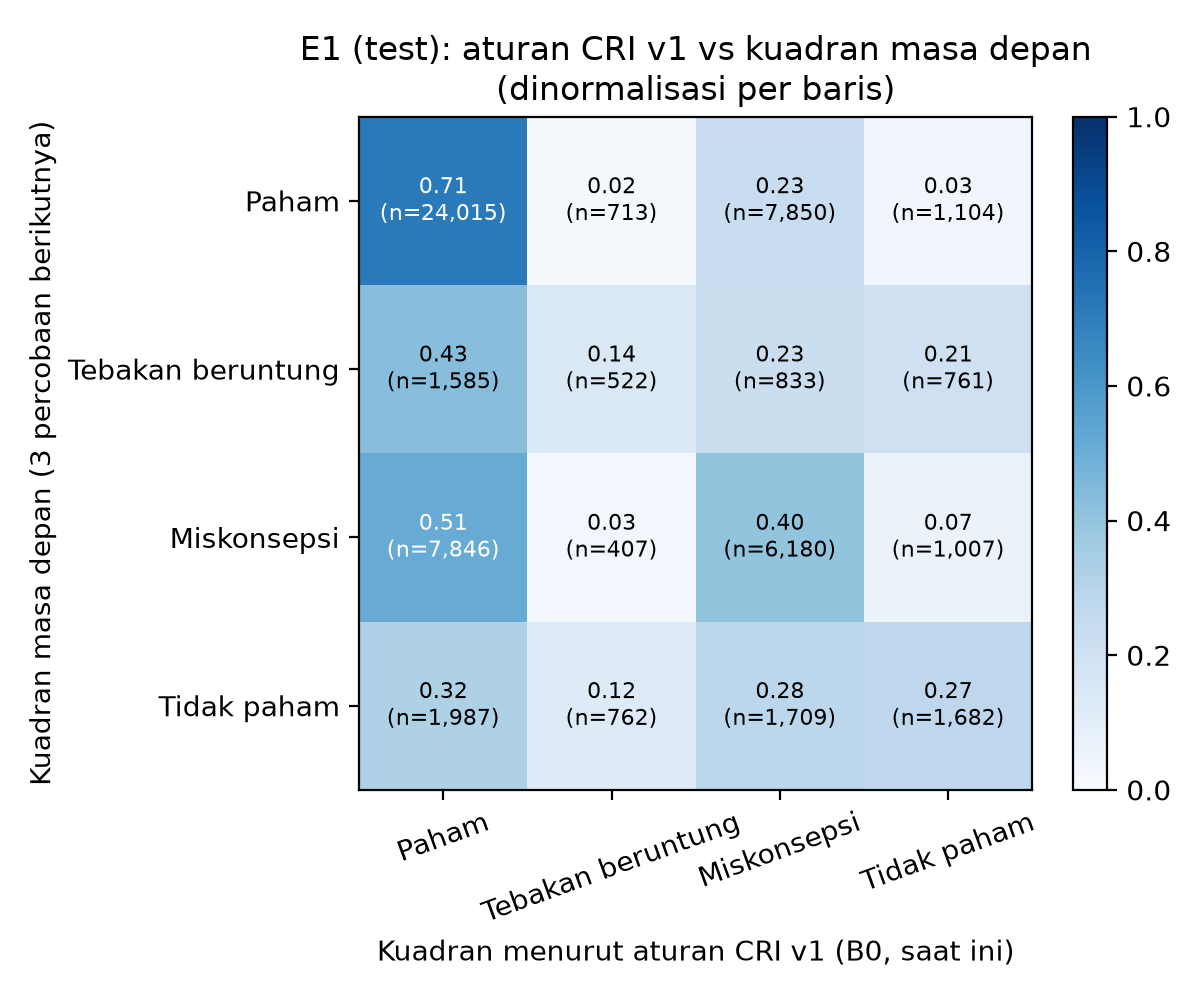

In [3]:
display(Image(FIGURES / 'E1_confusion_b0.png', width=500))

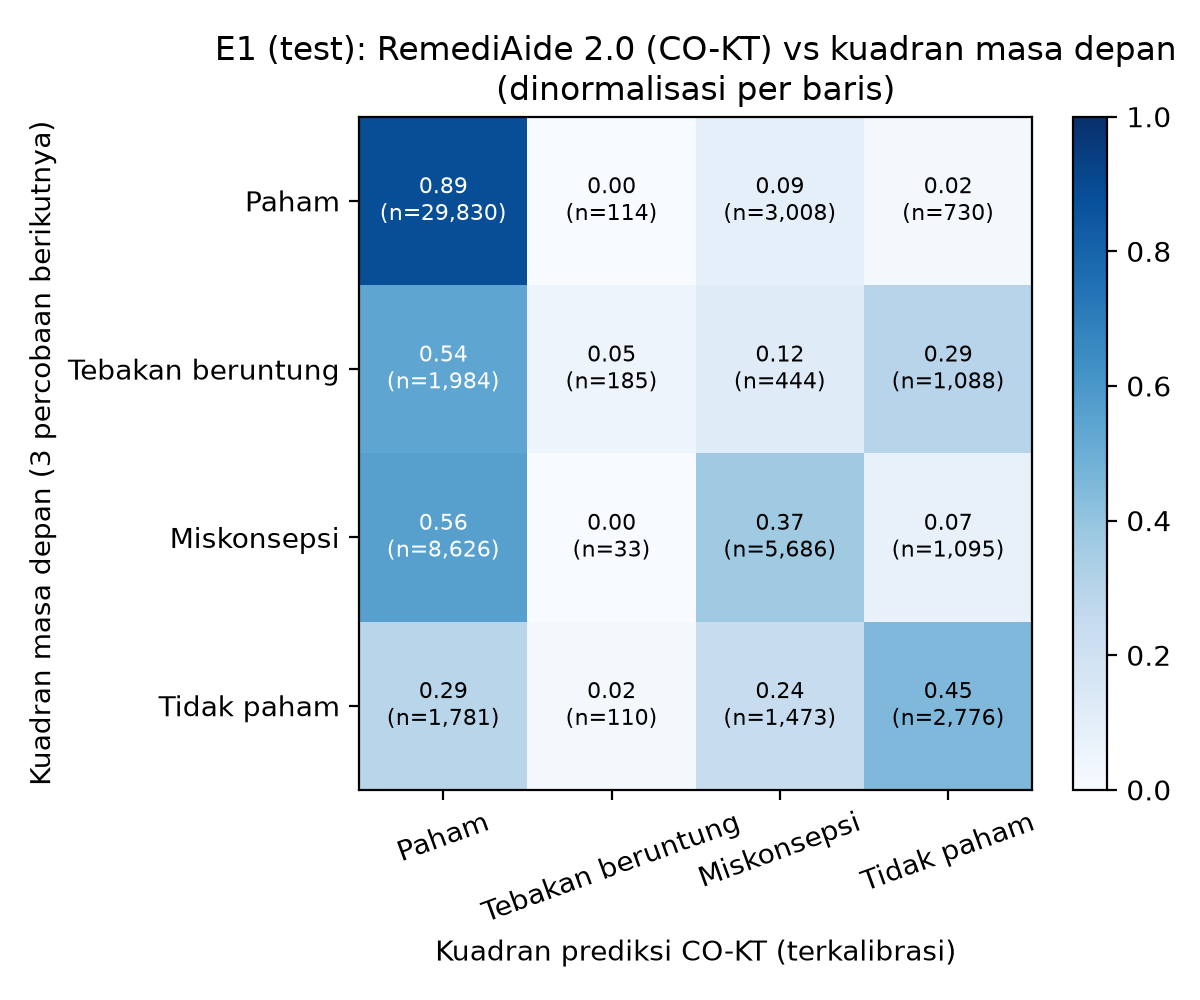

In [4]:
display(Image(FIGURES / 'E1_confusion_cokt.png', width=500))

## Semua model pada siswa test

In [5]:
pd.read_csv(TABLES / 'L1_test.csv')

,framing,model,metric,value,ci_lo,ci_hi,n_rows,ci_note
0,b,B0,macro_f1,0.3917,0.3799,0.4026,58963,1000 klaster siswa
1,b,B0,misgroup,0.4505,0.4314,0.4693,58963,1000 klaster siswa
2,b,B0,auc_needs_remediation,0.6313,0.6249,0.6374,226432,200 klaster siswa
3,b,B1a,macro_f1,0.1818,0.1758,0.1870,58963,1000 klaster siswa
4,b,B1a,misgroup,0.4288,0.4025,0.4577,58963,1000 klaster siswa
5,b,B1a,auc_needs_remediation,0.5576,0.5542,0.5610,226432,200 klaster siswa
6,b,B1b,macro_f1,0.3602,0.3497,0.3702,58963,1000 klaster siswa
7,b,B1b,misgroup,0.4006,0.3796,0.4220,58963,1000 klaster siswa
8,b,B1b,auc_needs_remediation,0.7341,0.7252,0.7426,226432,200 klaster siswa
9,b,LightGBM,macro_f1,0.4333,0.4167,0.4501,58963,1000 klaster siswa


In [6]:
pd.read_csv(TABLES / 'L1_test_pairwise.csv')

,perbandingan,selisih_salah_kelompok,ci_lo,ci_hi,p_mcnemar,selisih_auc_butuh_remediasi,p_delong,p_mcnemar_holm,p_delong_holm,selisih_auc_next_correct
0,CO-KT vs B0,-0.1031,-0.1091,-0.0972,0.0000e+00,0.1697,0.0000e+00,0.0000e+00,0.0000e+00,NaN
1,CO-KT vs B1b,-0.0532,-0.0586,-0.0479,2.7370e-204,0.0668,0.0000e+00,8.2111e-204,0.0000e+00,NaN
2,CO-KT vs LightGBM,-0.0141,-0.0176,-0.0106,4.8653e-22,0.0066,9.3249e-35,4.8653e-22,1.8650e-34,NaN
3,(a) CO-KT vs B1b,NaN,NaN,NaN,NaN,NaN,0.0000e+00,NaN,0.0000e+00,0.0493
4,(a) CO-KT vs LightGBM,NaN,NaN,NaN,NaN,NaN,2.0737e-06,NaN,2.0737e-06,0.0017


## E8 — dampak bagi guru (simulasi)

In [7]:
pd.read_csv(TABLES / 'E8_impact.csv')

,metrik,nilai
0,n_eval_rows,58963
1,n_eval_users,773
2,b0_misgroup,0.45051981751267745
3,ml_misgroup,0.34743822397096485
4,defer_rate,0.20560351406814442
5,ml_misgroup_kept,0.2831127241673783
6,b0_misgroup_on_kept,0.39225021349274125
7,errors_caught_by_defer,0.3526798789417163
8,ml_minus_b0_misgroup_ci,"[-0.10913394930335055, -0.097159542645712]"
9,teacher_reviews_per_class_32x15,98.7


## E6 — fairness

In [8]:
pd.read_csv(TABLES / 'E6_fairness.csv')

,atribut,kelompok_a,kelompok_b,metrik,nilai_a,nilai_b,selisih_a_minus_b,ci_lo,ci_hi,ci_memuat_0,n_siswa_a,n_siswa_b
0,Gender,perempuan,laki-laki,AUC butuh_remediasi,0.7934,0.8004,-0.0069,-0.0322,0.0159,True,294,303
1,Gender,perempuan,laki-laki,ECE,0.0237,0.0329,-0.0092,-0.0187,0.0027,True,294,303
2,Gender,perempuan,laki-laki,salah kelompok,0.3744,0.3265,0.0479,0.0047,0.0927,False,294,303
3,Gender,perempuan,laki-laki,tingkat defer,0.2367,0.1698,0.0669,0.0107,0.1239,False,294,303
4,PremiumPupil,pupil premium,bukan,AUC butuh_remediasi,0.7330,0.8043,-0.0712,-0.0957,-0.0489,False,107,308
5,PremiumPupil,pupil premium,bukan,ECE,0.0509,0.0185,0.0324,0.0182,0.0445,False,107,308
6,PremiumPupil,pupil premium,bukan,salah kelompok,0.4489,0.3278,0.1211,0.0722,0.1729,False,107,308
7,PremiumPupil,pupil premium,bukan,tingkat defer,0.2927,0.1765,0.1162,0.0286,0.2116,False,107,308
8,ability_q,kuartil 1,kuartil 4,AUC butuh_remediasi,0.6383,0.7976,-0.1594,-0.1789,-0.1389,False,246,246
9,ability_q,kuartil 1,kuartil 4,ECE,0.0925,0.0264,0.0661,0.0594,0.0737,False,246,246


## Robustness temporal

In [9]:
pd.read_csv(TABLES / 'robustness_temporal_test.csv')

,subset,model,metric,value,ci_lo,ci_hi,n_rows
0,20% interaksi terakhir per siswa,B0,macro_f1,0.3892,0.3619,0.4127,7102
1,20% interaksi terakhir per siswa,B0,misgroup,0.4841,0.4550,0.5133,7102
2,20% interaksi terakhir per siswa,LightGBM,macro_f1,0.4308,0.4055,0.4542,7102
3,20% interaksi terakhir per siswa,LightGBM,misgroup,0.4112,0.3855,0.4389,7102
4,20% interaksi terakhir per siswa,CO-KT,macro_f1,0.4539,0.4231,0.4777,7102
5,20% interaksi terakhir per siswa,CO-KT,misgroup,0.3888,0.3654,0.4150,7102
